In [1]:
%load_ext autoreload
%autoreload 2

# Load hardware data

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"
# device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_6824/664675149.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

2 possible layouts


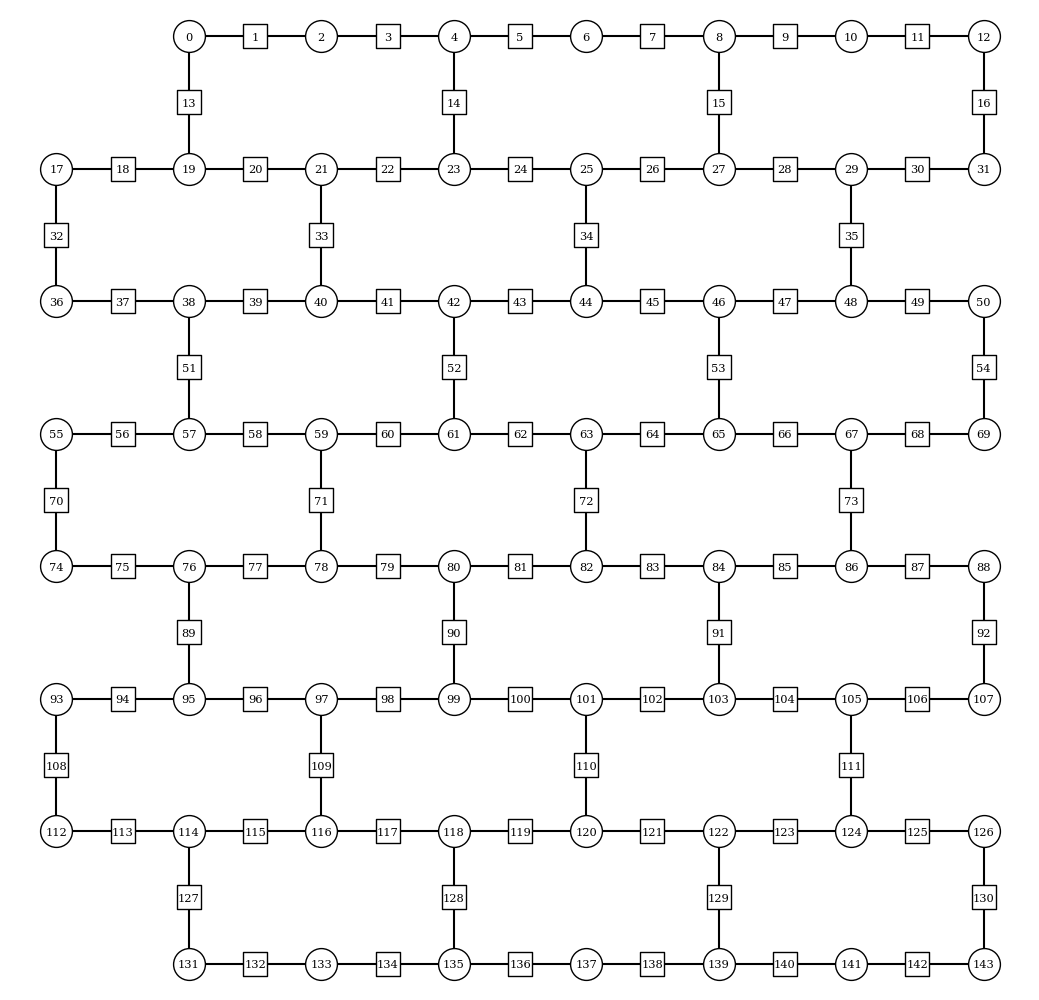

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 7

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

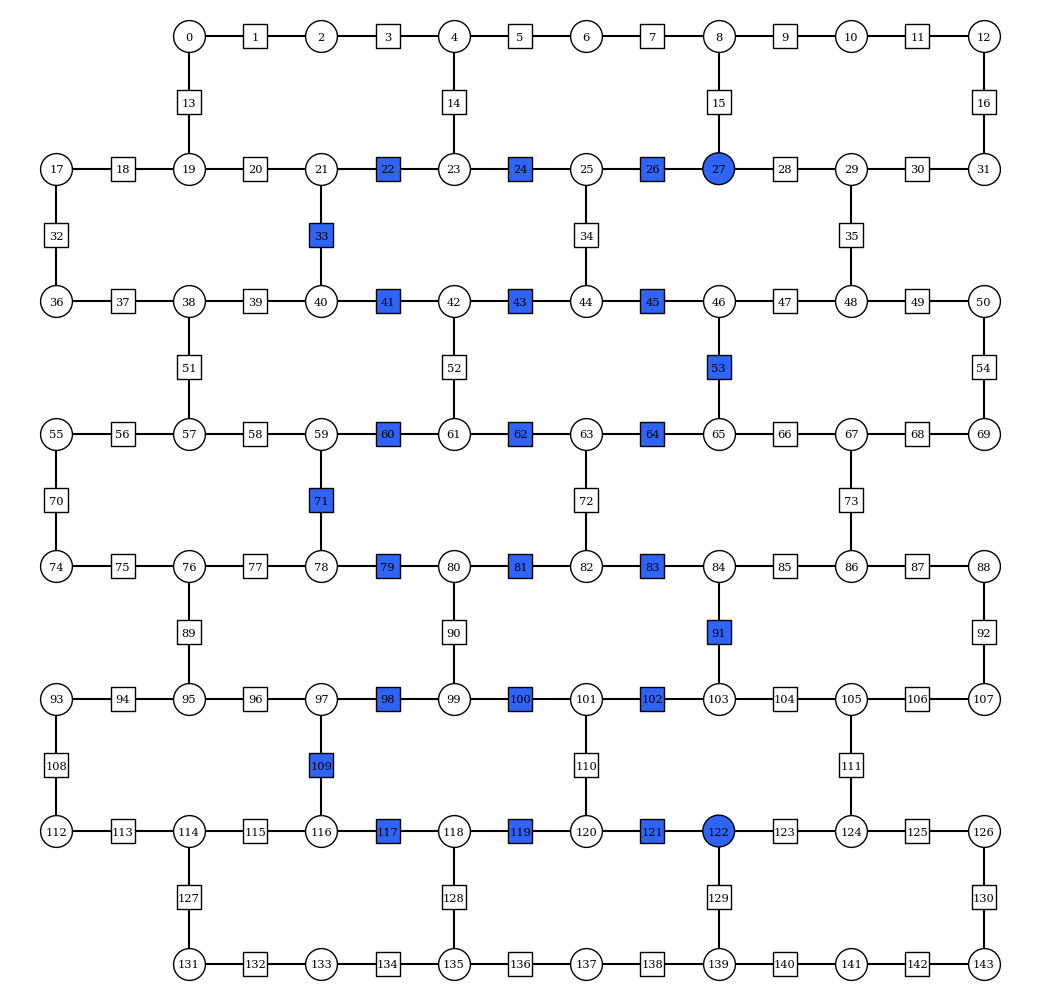

In [4]:
from z2hex.gdd import zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 0
h = 0
lamb = 1

x_basis = False

fractional_gates = False

string = [27, 26, 24, 22, 33, 41, 43, 45, 53, 64, 62, 60, 71, 79, 81, 83, 91, 102, 100, 98, 109, 117, 119, 121, 122] # Benchmark

final_time = 7.5
dt = 0.25
steps = 60
desired_error = 1e-2

max_layers = 50
adjust_depth = True

shots = 300000
confidence = 0.9

odr = True
postselect_odr = True
flip_threshold = 1
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 4
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
# g_func = zero_mean

sampler_options_args = [(False, False), (False, True)] # (DD, PT)
g_funcs = [None, zero_mean]

sampler_options = [{
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": a[0],
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": a[1],
        "enable_measure": a[1],
        "num_randomizations": "auto",
        "shots_per_randomization": "auto"
    },
    "experimental": {
        "execution_path": "gen3-turbo"
    }
} for a in sampler_options_args]

execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

curated_data_folder_path = "Curated data/"

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True)

## Load jobs

In [5]:
from itertools import product
import pickle
import os

hardware_datas = [] # [(hardware_observables, hardware_observables_confidence, samples_dicts, postselected_samples_dicts, layouts)]

to_iterate = [(None, sampler_options[0]), (zero_mean, sampler_options[0]), (zero_mean, sampler_options[1])]

for g_func, sampler_dict in to_iterate: #product(g_funcs, sampler_options):
    data_filepath = os.path.join(curated_data_folder_path, f"z2hexquench_curated_data_{device}_px_{lattice_dims[0]}_py_{lattice_dims[1]}_maxt_{final_time}_dt_{dt}_steps_{steps}_J_{J:.04f}_h_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else g_func}_shots_{shots}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string[:10]])}_xbasis_{x_basis}_dd_{sampler_dict["dynamical_decoupling"]["enable"]}_pt_{sampler_dict["twirling"]["enable_gates"]}_ft_{flip_threshold}_pODR_{postselect_odr}_confidence_{confidence}.pkl")
    with open(data_filepath, "rb") as f:
        hardware_datas.append(pickle.load(f))

# Load TN data

In [6]:
import numpy as np
import os

tn_dt = 0.01
tn_final_time = 16
tn_exp_order = 30
tn_bond_dimension = 128
tn_data_folderpath = "TN Data/"
tn_data_limit = int(final_time / tn_dt)

filename = "converted_data_1string_BUG_g2.00_m5.00_3x6_dt0.010_Tmax16.00_exp_order30_M00064.txt"

tn_data_filepath = os.path.join(tn_data_folderpath, f"converted_data_1string_BUG_g2.00_m5.00_3x6_dt0.010_Tmax16.00_exp_order30_M00064.txt")
tn_observables = np.loadtxt(tn_data_filepath)

KeyboardInterrupt: 

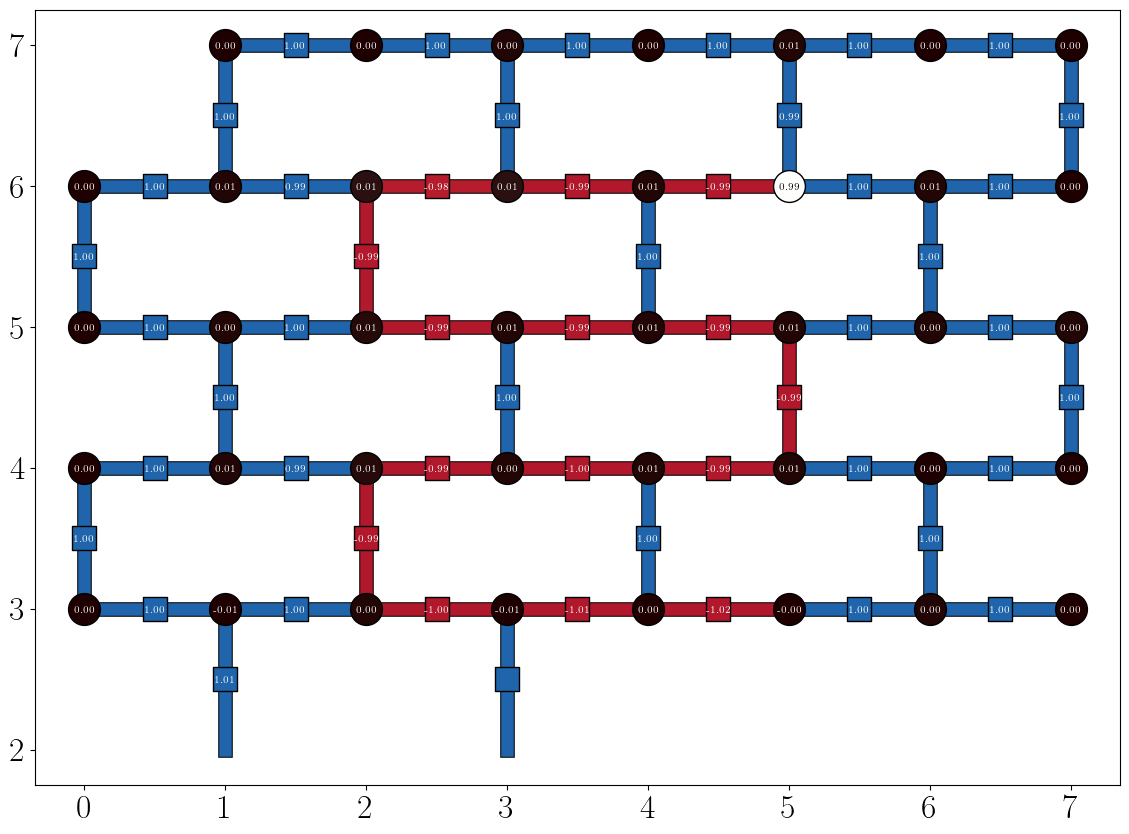

In [7]:
from z2hex.plotting import local_obs_anim, truncate_colormap
import matplotlib.pyplot as plt
from copy import deepcopy

interpolation_frames = 17
fps = 30
frame_to_title_func = lambda frame: f"$t = {final_time * frame / ((interpolation_frames+1)*steps):.02f}$"

cmap_matter = truncate_colormap(plt.get_cmap("pink"), 0, 1)
cmap_gauge = truncate_colormap(plt.get_cmap("RdBu"), 0.1, 0.9)

cmap_range_matter = [0, 1]
cmap_range_gauge = [-1, 1]
cmap_label_matter = r"$(1 - \langle Z \rangle_{\mathrm{matter}})/2$"
cmap_label_gauge = r"$\langle Z \rangle_{\mathrm{gauge}}$"

matter_qb_inds = lattice.node_qbinds
observables_to_plot = deepcopy(hardware_datas[0][0])
for i, obs in enumerate(observables_to_plot):
    observables_to_plot[i][:, matter_qb_inds] = (1 - obs[:, matter_qb_inds]) / 2

postselected_odr_filepath = f"z2hex_string_quench_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
postselected_filepath = f"z2hex_string_quench_nodr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
odr_filepath = f"z2hex_string_quench_odr_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
raw_filepath = f"z2hex_string_quench_raw_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.mp4"
local_obs_anim(observables_to_plot[0], lattice, frame_to_title_func, interpolation_frames=interpolation_frames, fps=fps, cmap_matter=cmap_matter, cmap_gauge=cmap_gauge, cmap_range_matter=cmap_range_matter, cmap_label_matter=cmap_label_matter, cmap_label_gauge=cmap_label_gauge, filepath=postselected_odr_filepath, dark_theme=False)

# Plots

## No ODR and rest of error mitigation strategies

### Absolute value

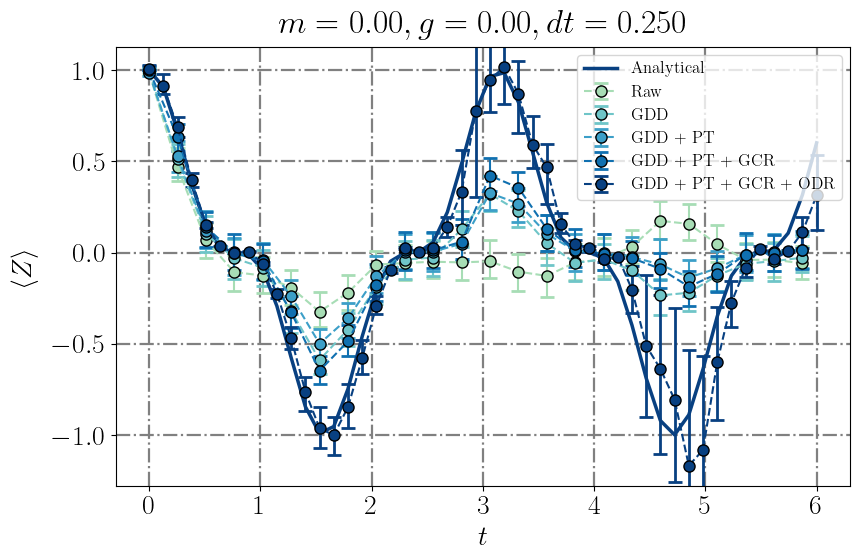

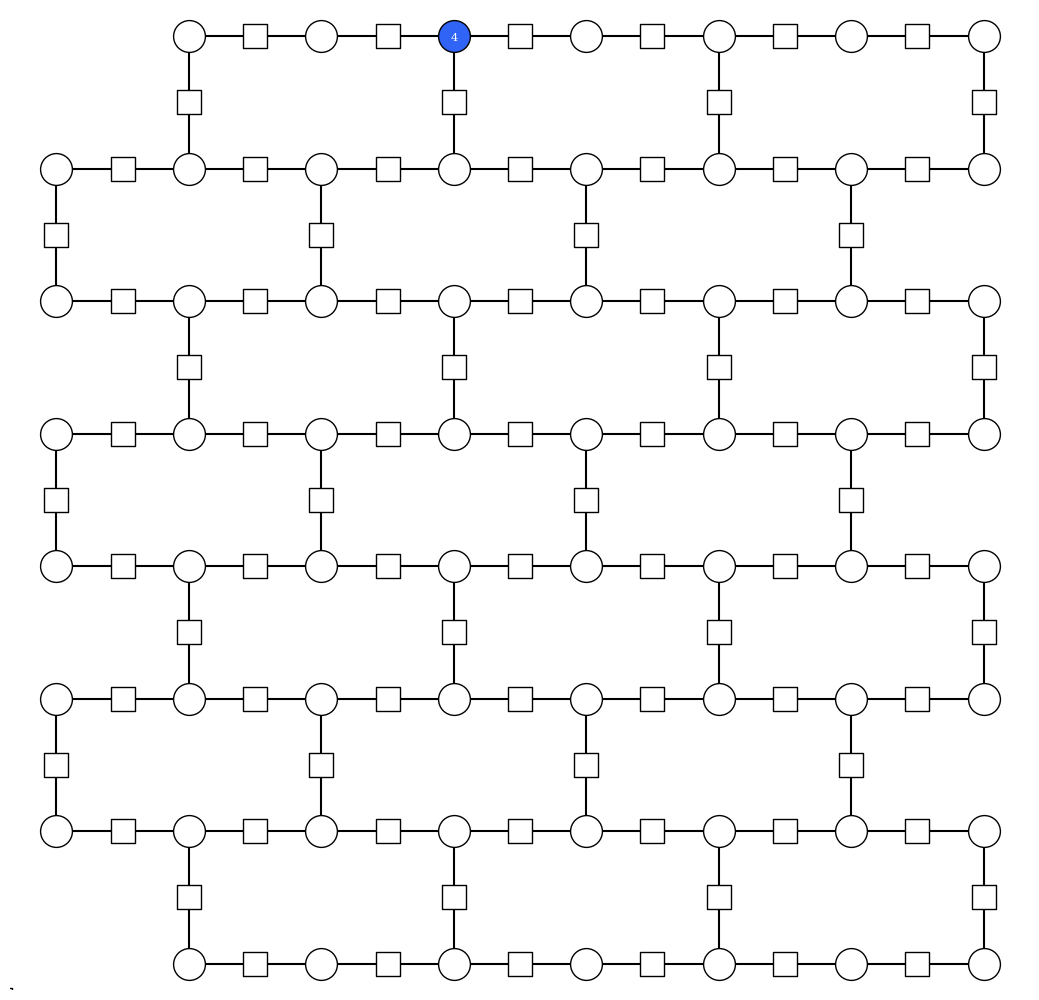

In [13]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt
import numpy as np

qubit = 4

plot_upto_time = 6
plot_upto = int(np.ceil(steps*plot_upto_time/final_time))
plot_step = 1

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, plot_upto_time, 7))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12
y_lim = "data"

funclabels = [
    "Raw",
    "GDD",
    "GDD + PT",
    "GDD + PT + GCR",
    "GDD + PT + GCR + ODR",
    "Analytical"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][3][:, qubit] for hdata in hardware_datas] + [hardware_datas[-1][0][1][:, qubit], hardware_datas[-1][0][0][:, qubit]])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 2, 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][3][:, qubit, :]
hardware_observables_confidences_to_plot[:, -2, :] = hardware_datas[-1][1][1][:, qubit, :]    
hardware_observables_confidences_to_plot[:, -1, :] = hardware_datas[-1][1][0][:, qubit, :]

hardware_observables_to_plot = hardware_observables_to_plot[:plot_upto:plot_step, :]
hardware_observables_confidences_to_plot = hardware_observables_confidences_to_plot[:plot_upto:plot_step, :, :]

# hardware_observables_to_plot[::2, :-1] = np.nan
# hardware_observables_confidences_to_plot[::2, :-1, :] = np.nan

tn_observable_to_plot = None #tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, lambda x: np.cos(2*x)**3, fmt="o--", x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, y_lim=y_lim, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

In [28]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 18

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [
    "GDD",
    "GDD + PT",
    "GDD + PT + DD",
    "GDD + PT + DD + REC",
    "GDD + PT + DD + REC + ODR",
    "MPS"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][3][:, qubit] for hdata in hardware_datas] + [hardware_datas[-1][0][1][:, qubit], hardware_datas[-1][0][0][:, qubit]])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 2, 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][3][:, qubit, :]
hardware_observables_confidences_to_plot[:, -2, :] = hardware_datas[-1][1][1][:, qubit, :]    
hardware_observables_confidences_to_plot[:, -1, :] = hardware_datas[-1][1][0][:, qubit, :]

tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

NameError: name 'tn_observables' is not defined

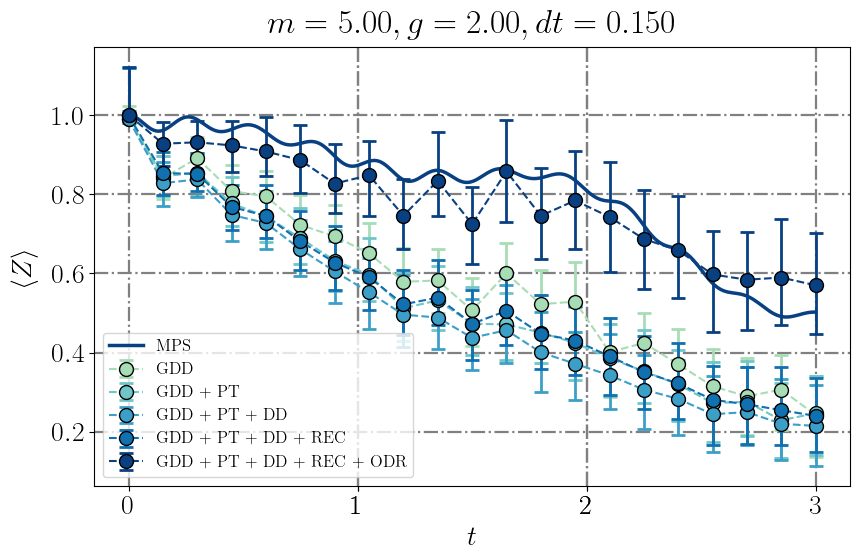

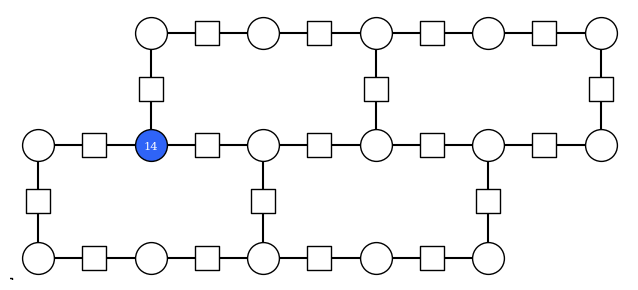

In [19]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 14

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [
    "GDD",
    "GDD + PT",
    "GDD + PT + DD",
    "GDD + PT + DD + REC",
    "GDD + PT + DD + REC + ODR",
    "MPS"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][3][:, qubit] for hdata in hardware_datas] + [hardware_datas[-1][0][1][:, qubit], hardware_datas[-1][0][0][:, qubit]])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 2, 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][3][:, qubit, :]
hardware_observables_confidences_to_plot[:, -2, :] = hardware_datas[-1][1][1][:, qubit, :]    
hardware_observables_confidences_to_plot[:, -1, :] = hardware_datas[-1][1][0][:, qubit, :]

tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

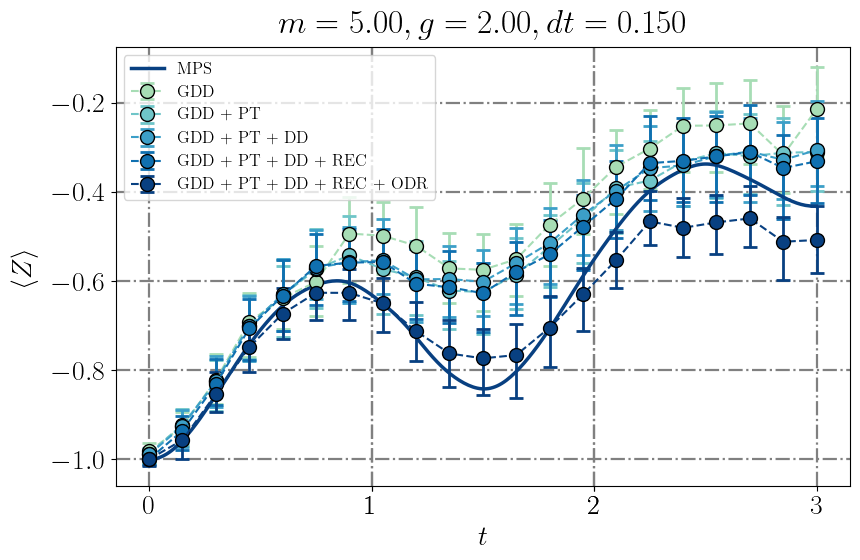

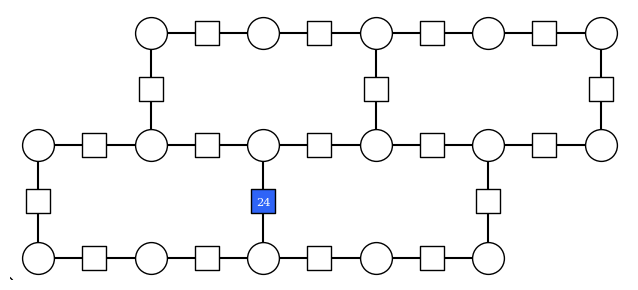

In [27]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 24

cmap = lambda x: plt.get_cmap("GnBu")((1.25*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [
    "GDD",
    "GDD + PT",
    "GDD + PT + DD",
    "GDD + PT + DD + REC",
    "GDD + PT + DD + REC + ODR",
    "MPS"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_nODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hdata[0][3][:, qubit] for hdata in hardware_datas] + [hardware_datas[-1][0][1][:, qubit], hardware_datas[-1][0][0][:, qubit]])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 2, 2))
for i, hdata in enumerate(hardware_datas):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][3][:, qubit, :]
hardware_observables_confidences_to_plot[:, -2, :] = hardware_datas[-1][1][1][:, qubit, :]    
hardware_observables_confidences_to_plot[:, -1, :] = hardware_datas[-1][1][0][:, qubit, :]

tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

## Always ODR and rest of error mitigation strategies

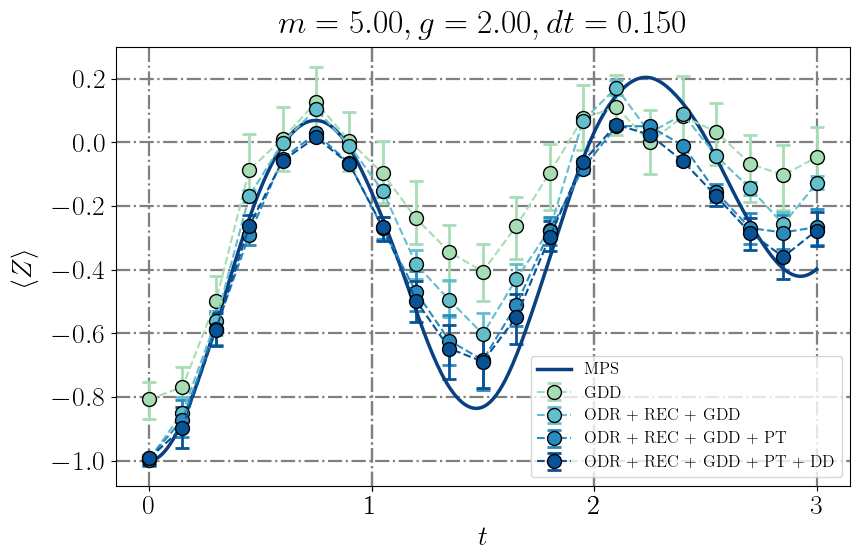

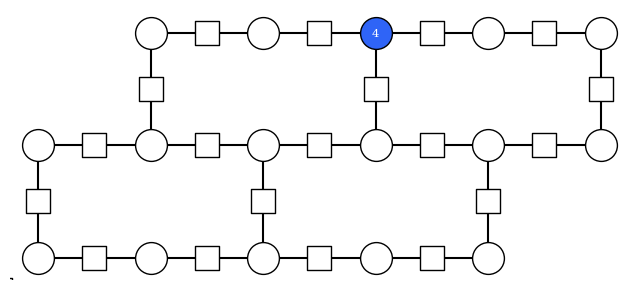

In [21]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 4

cmap = lambda x: plt.get_cmap("GnBu")((1.5*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [
    "GDD",
    "ODR + REC + GDD",
    "ODR + REC + GDD + PT",
    "ODR + REC + GDD + PT + DD",
    "MPS"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hardware_datas[0][0][3][:, qubit]] + [hdata[0][0][:, qubit] for hdata in hardware_datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 1, 2))
hardware_observables_confidences_to_plot[:, 0, :] = hardware_datas[0][1][3][:, qubit, :]
for i, hdata in enumerate(hardware_datas, start=1):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

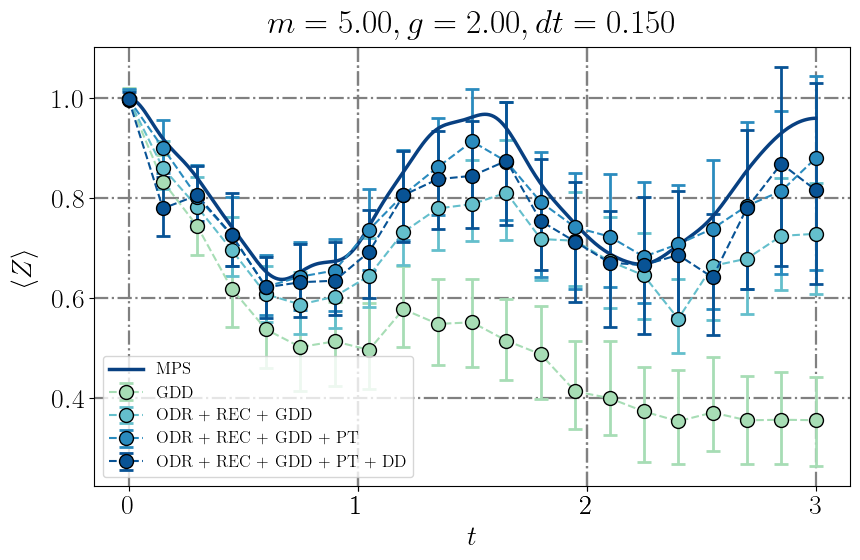

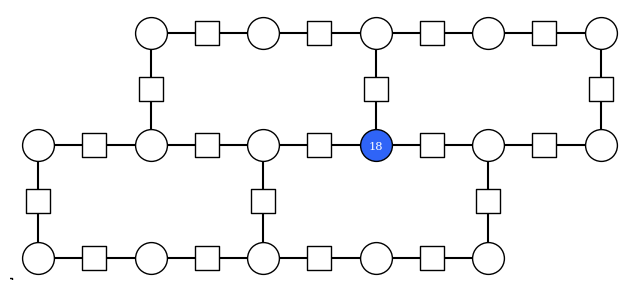

In [28]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 18

cmap = lambda x: plt.get_cmap("GnBu")((1.5*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [
    "GDD",
    "ODR + REC + GDD",
    "ODR + REC + GDD + PT",
    "ODR + REC + GDD + PT + DD",
    "MPS"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hardware_datas[0][0][3][:, qubit]] + [hdata[0][0][:, qubit] for hdata in hardware_datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 1, 2))
hardware_observables_confidences_to_plot[:, 0, :] = hardware_datas[0][1][3][:, qubit, :]
for i, hdata in enumerate(hardware_datas, start=1):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

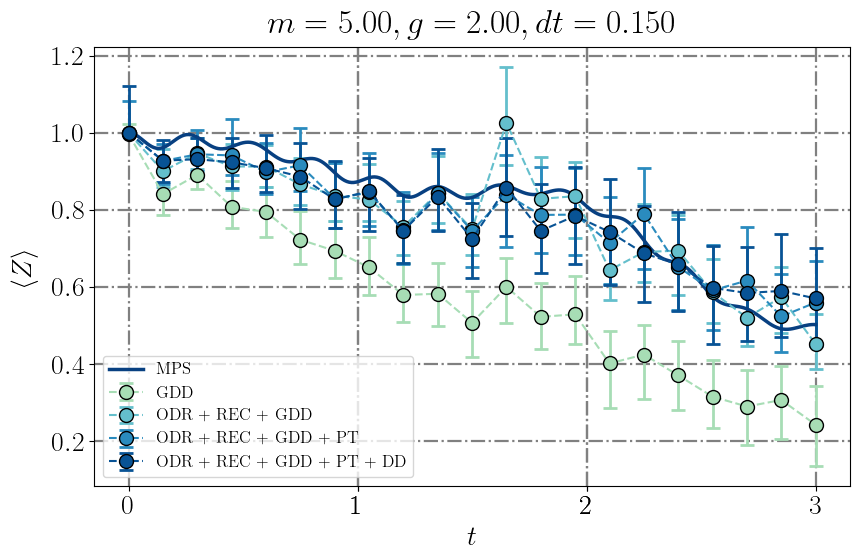

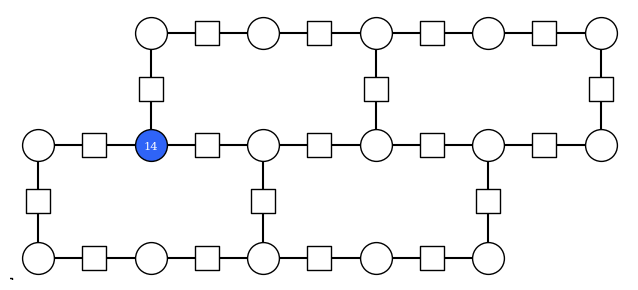

In [23]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 14

cmap = lambda x: plt.get_cmap("GnBu")((1.5*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [
    "GDD",
    "ODR + REC + GDD",
    "ODR + REC + GDD + PT",
    "ODR + REC + GDD + PT + DD",
    "MPS"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hardware_datas[0][0][3][:, qubit]] + [hdata[0][0][:, qubit] for hdata in hardware_datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 1, 2))
hardware_observables_confidences_to_plot[:, 0, :] = hardware_datas[0][1][3][:, qubit, :]
for i, hdata in enumerate(hardware_datas, start=1):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

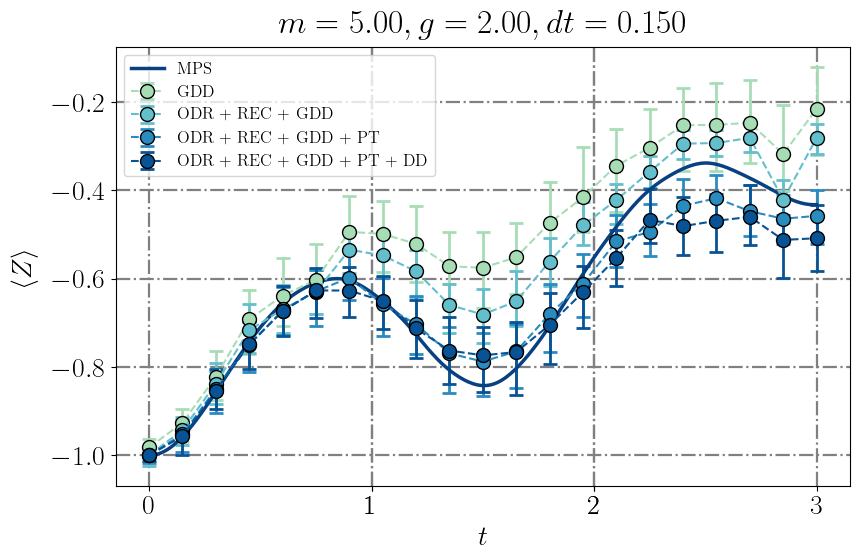

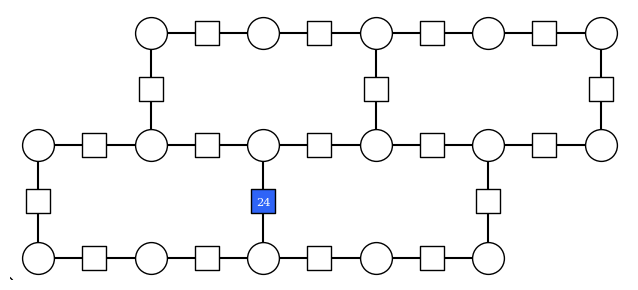

In [24]:
from utils.plotting import plot_individual_qubits_observable_evolution
import matplotlib.pyplot as plt

qubit = 24

cmap = lambda x: plt.get_cmap("GnBu")((1.5*(x)+3)/8)
markers = None #["v", "^"]
title = rf"$m = {J:.02f}, g = {h:.02f}, dt = {dt:.03f}$"
legend = False
x_ticks = np.round(np.linspace(0, final_time, 6))
x_label = r"$t$"
y_label = r"$\langle Z \rangle$"
legend_fontsize = 12

funclabels = [
    "GDD",
    "ODR + REC + GDD",
    "ODR + REC + GDD + PT",
    "ODR + REC + GDD + PT + DD",
    "MPS"
]

plot_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_{device}_postselection_maxt_{final_time:.02f}_steps_{steps}_m_{J:.04f}_g_{h:.04f}_lamb_{lamb:.04f}_g_{g_func.__name__ if callable(g_func) else None}_fqb_{all_or_first_layout_qubit}_string_{"-".join([str(i) for i in string])}_xbasis_{x_basis}.pdf"
legend_filepath = f"z2hex_quench_qubits_nmcomp_qb_{qubit}_aODR_legend_px_{plaquette_width}_py_{plaquette_height}_string_{"-".join([str(i) for i in string])}.pdf"

hardware_observables_to_plot = np.column_stack([hardware_datas[0][0][3][:, qubit]] + [hdata[0][0][:, qubit] for hdata in hardware_datas])
hardware_observables_confidences_to_plot = np.zeros((hardware_observables_to_plot.shape[0], len(hardware_datas) + 1, 2))
hardware_observables_confidences_to_plot[:, 0, :] = hardware_datas[0][1][3][:, qubit, :]
for i, hdata in enumerate(hardware_datas, start=1):
    hardware_observables_confidences_to_plot[:, i, :] = hdata[1][0][:, qubit, :]
tn_observable_to_plot = tn_observables[:tn_data_limit, qubit]

plot_individual_qubits_observable_evolution(hardware_observables_to_plot, hardware_observables_confidences_to_plot, tn_observable_to_plot, x_ticks=x_ticks, x_label=x_label, ylabel=y_label, title=title, cmap=cmap, funclabels=funclabels, legend_fontsize=legend_fontsize, filepath=plot_filepath)
lattice.plot_highlighted_qubits([qubit], colors=["#2f64f7"], filepath=legend_filepath)

## All EM, single and many layouts